# Validation and limitations

Phase O. Does the predicted surface look right, and what are its limits? Three checks that do not need new ground data: whether the predicted seasonal cycle follows the observed one, whether a set of places known to be polluted or clean come out high or low, and how far the validated range of the model reaches compared with where it was applied. The notebook ends with the numbers that go into the limitations section of the report.

In [1]:
%load_ext autoreload
%autoreload 2

## Imports

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import yaml
from scipy.stats import spearmanr

import monitoring_deserts.data.fetch_population as fetch_pop

## Configuration

Read the general project config and define the places for the spot check.

In [3]:
# Generic settings
with open("../configs/project_config.yaml") as f:
    gen_config = yaml.safe_load(f)

PROCESSED_DATA_DIR = Path(gen_config["data_dir"]["processed"]) # The data/processed/ should have no subdirs
CLEAN_DATA_DIR = Path(gen_config["data_dir"]["clean"])
PLOTS_DIR = Path(gen_config["output_dir"]["plots"]) / "validation"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

CELL_SIZE = gen_config["grid_cell_size_deg"]

# Places for the spot check: name -> (longitude, latitude, what is expected)
SPOT_CHECKS = {
    "Delhi": (77.21, 28.61, "high"),
    "Lahore": (74.34, 31.55, "high"),
    "Lucknow": (80.95, 26.85, "high"),
    "Patna": (85.14, 25.59, "high"),
    "Dhaka": (90.41, 23.81, "high"),
    "Kolkata": (88.36, 22.57, "high"),
    "Leh (Ladakh)": (77.58, 34.16, "low"),
    "Munnar (Western Ghats)": (77.06, 10.09, "low"),
    "Nuwara Eliya (Sri Lanka)": (80.77, 6.97, "low"),
    "Port Blair (Andaman)": (92.74, 11.62, "low"),
    "Arabian Sea": (65.00, 15.00, "ocean"),
}
HIGH_PERCENTILE, LOW_PERCENTILE = 0.75, 0.25 # crude thresholds for 'high' and 'low' among populated cells

## Outline

1. ~~**Step 1 - Assemble the cell table.** Predictions (with the calendar-balanced mean), population, distance to the nearest station and the out-of-range indicator for every cell.~~
2. ~~**Step 2 - Seasonal cycle.** Does the population-weighted predicted PM2.5 follow the month-to-month changes seen at the stations?~~
3. ~~**Step 3 - Spot checks.** Known polluted and clean places: where do their cells fall in the distribution of predictions?~~
4. ~~**Step 4 - Numbers for the limitations section.** How far the validated range reaches compared with where the model was applied, and what the grid contains besides populated land.~~
5. ~~**Step 5 - Save.**~~

## Step 1 - Assemble the cell table

The study period has 16 months, so March to June appear twice and the other months once. A plain mean over the 16 months would weight spring more than the rest of the year. The calendar-balanced mean used for the spot checks averages each calendar month over the years available first, and then averages the 12 months equally.

In [4]:
grid = gpd.read_parquet(PROCESSED_DATA_DIR / "grid.parquet")[["cell_id", "centroid_lon", "centroid_lat"]]
population = pd.read_parquet(CLEAN_DATA_DIR / "population" / "grid_features.parquet", columns=["cell_id", "population"])
status = pd.read_parquet(PROCESSED_DATA_DIR / "cell_monitoring_status.parquet", columns=["cell_id", "distance_to_station_km"])

monthly = pd.read_parquet(
    PROCESSED_DATA_DIR / "grid_predictions.parquet",
    columns=["cell_id", "month", "predicted_pm25", "pm25_lower", "pm25_upper", "n_features_out_of_range"],
)
monthly["month_of_year"] = monthly["month"].dt.month

# Calendar-balanced mean: each calendar month averaged over the years, then the 12 months averaged
per_calendar_month = monthly.groupby(["cell_id", "month_of_year"])[["predicted_pm25", "pm25_lower", "pm25_upper"]].mean()
balanced = per_calendar_month.groupby("cell_id").mean().rename(columns={"predicted_pm25": "pm25", "pm25_lower": "pm25_low", "pm25_upper": "pm25_high"})
out_of_range = monthly.groupby("cell_id")["n_features_out_of_range"].mean().rename("mean_features_out_of_range")

cells = (
    grid.merge(population, on="cell_id", how="left", validate="one_to_one")
        .merge(status, on="cell_id", how="left", validate="one_to_one")
        .merge(balanced, on="cell_id", how="left", validate="one_to_one")
        .merge(out_of_range, on="cell_id", how="left", validate="one_to_one")
)
populated = cells["population"].gt(0)

# Raster position of every cell, as in the earlier notebooks
grid_lons = np.sort(cells["centroid_lon"].round(9).unique())
grid_lats = np.sort(cells["centroid_lat"].round(9).unique())
cells["col"] = np.searchsorted(grid_lons, cells["centroid_lon"].round(9).values)
cells["lat_idx"] = np.searchsorted(grid_lats, cells["centroid_lat"].round(9).values)

print(f"{len(cells):,} cells; {populated.sum():,} populated; {cells['pm25'].isna().sum():,} without a prediction")

434,940 cells; 155,033 populated; 0 without a prediction


## Step 2 - Seasonal cycle

A sanity check on the time dimension: the predicted national cycle should rise and fall with the observed one. The prediction is the population-weighted mean over populated cells for each of the 16 months, the observation the mean over all stations that reported that month. The two are different populations (stations are in towns and the population-weighted grid mean covers rural areas as well), so the levels will differ; what is checked is the shape.

{'months': 16, 'pearson': 0.9777277068285535, 'spearman': 0.9705882352941176}


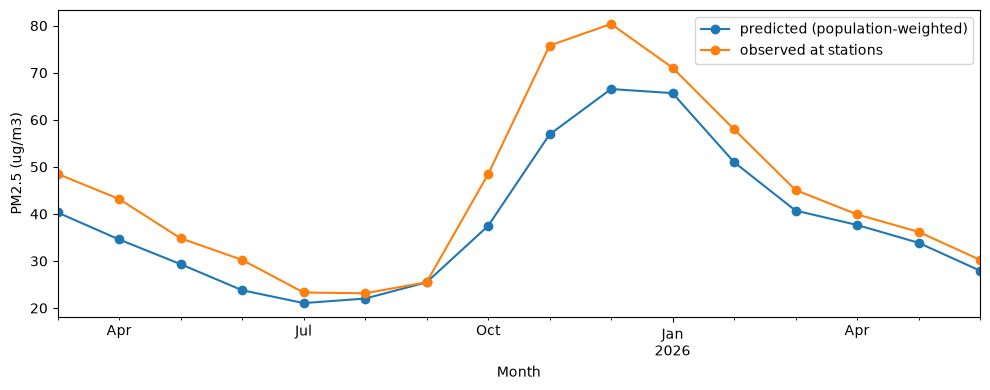

,predicted (population-weighted),observed at stations
month,,
2025-03,40.300697,48.513575
2025-04,34.568684,43.169492
2025-05,29.323284,34.820142
2025-06,23.788803,30.233962
2025-07,21.051699,23.306023
2025-08,22.012747,23.137876
2025-09,25.460634,25.478031
2025-10,37.440414,48.416574
2025-11,56.880955,75.765716


In [5]:
populated_ids = cells.loc[populated, "cell_id"]
weights = cells.set_index("cell_id")["population"]

in_populated = monthly[monthly["cell_id"].isin(populated_ids)].copy()
in_populated["weight"] = in_populated["cell_id"].map(weights)
in_populated["weighted"] = in_populated["predicted_pm25"] * in_populated["weight"]
by_month = in_populated.groupby("month")[["weighted", "weight"]].sum()
predicted_cycle = (by_month["weighted"] / by_month["weight"]).rename("predicted (population-weighted)")

station_months = pd.read_parquet(PROCESSED_DATA_DIR / "master_station_df.parquet", columns=["station_id", "month", "pm25"])
observed_cycle = station_months.groupby("month")["pm25"].mean().rename("observed at stations")

cycle = pd.concat([predicted_cycle, observed_cycle], axis=1).dropna()
cycle_agreement = {
    "months": int(len(cycle)),
    "pearson": float(np.corrcoef(cycle.iloc[:, 0], cycle.iloc[:, 1])[0, 1]),
    "spearman": float(spearmanr(cycle.iloc[:, 0], cycle.iloc[:, 1])[0]),
}
print(cycle_agreement)

fig, ax = plt.subplots(figsize=(10, 4))
cycle.plot(ax=ax, marker="o")
ax.set_ylabel("PM2.5 (ug/m3)")
ax.set_xlabel("Month")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "seasonal_cycle.png", dpi=150)
plt.show()
cycle

Reading notes: both lines should rise and fall together. The predicted line is a model output driven by the weather features, so a poor match would point to a problem in the grid features or the month encoding, not just in the level. The observed line is the station mean, which also changes with which stations report in a given month.

## Step 3 - Spot checks

Known places and what to expect: the large cities of the Indo-Gangetic Plain should be high, the high mountains, the Western Ghats, the Sri Lankan hills and the Andaman Islands low, and a point in the open sea has no stations and no meaning (the grid has no land mask, so the sea is predicted too). For each place the table gives the prediction of the nearest cell, its band, its distance to a station, and the **percentile** of the prediction among all populated cells (0.9 means 90% of populated cells are predicted lower). The last column applies a crude rule: 'high' places should be in the top quarter and 'low' places in the bottom quarter. It is a plausibility pass that catches gross pipeline errors, not a test.

In [6]:
spot_cols, spot_lat_idx = fetch_pop.locate_grid_cells(
    [v[0] for v in SPOT_CHECKS.values()], [v[1] for v in SPOT_CHECKS.values()], grid_lons, grid_lats, CELL_SIZE
)
lookup = cells.set_index(["lat_idx", "col"])
populated_pm25 = np.sort(cells.loc[populated, "pm25"].dropna().to_numpy())

rows = []
for (name, (lon, lat, expected)), col, lat_idx in zip(SPOT_CHECKS.items(), spot_cols, spot_lat_idx):
    cell = lookup.loc[(lat_idx, col)]
    percentile = np.searchsorted(populated_pm25, cell["pm25"]) / len(populated_pm25)
    consistent = (percentile >= HIGH_PERCENTILE) if expected == "high" else (percentile <= LOW_PERCENTILE) if expected == "low" else None
    rows.append({
        "place": name, "expected": expected, "predicted_pm25": cell["pm25"], "band_low": cell["pm25_low"], "band_high": cell["pm25_high"],
        "percentile_among_populated": percentile, "distance_to_station_km": cell["distance_to_station_km"],
        "mean_features_out_of_range": cell["mean_features_out_of_range"], "consistent": consistent,
    })
spot_table = pd.DataFrame(rows).set_index("place")
spot_table.style.format({"predicted_pm25": "{:.1f}", "band_low": "{:.1f}", "band_high": "{:.1f}", "percentile_among_populated": "{:.2f}",
                         "distance_to_station_km": "{:.0f}", "mean_features_out_of_range": "{:.1f}"})

,expected,predicted_pm25,band_low,band_high,percentile_among_populated,distance_to_station_km,mean_features_out_of_range,consistent
place,,,,,,,,
Delhi,high,56.3,27.6,118.9,0.99,3,0.1,True
Lahore,high,58.0,28.4,122.4,1.00,2,0.2,True
Lucknow,high,48.4,23.6,102.4,0.90,2,0.0,True
Patna,high,46.3,22.6,97.9,0.86,2,0.2,True
Dhaka,high,50.9,24.9,107.7,0.95,15,0.3,True
Kolkata,high,44.6,21.7,94.4,0.81,3,0.4,True
Leh (Ladakh),low,37.5,18.2,79.6,0.54,256,3.8,False
Munnar (Western Ghats),low,23.2,11.1,49.6,0.01,96,1.9,True
Nuwara Eliya (Sri Lanka),low,21.1,10.0,45.1,0.01,453,1.8,True


Reading notes: a place that fails the rule is not necessarily wrong (a hill station next to a plain may sit in a cell of mixed terrain, and a cell is 5 km across), but a group of failures in the same direction, or a clean mountain at the top of the distribution, would point to a pipeline error. A high out-of-range count on a place says the prediction there rests on extrapolated features.

## Step 4 - Numbers for the limitations section

These figures support the limitations written below: how far the validated range of the model reaches compared with where it was applied, how unlike the stations the grid is, and what the grid contains besides populated land.

In [7]:
with open("../configs/cross_validation_metadata.yaml") as f:
    distance_check = yaml.safe_load(f)["distance_check_km"]
distance_table = pd.DataFrame(distance_check).T
print("Distance to the nearest (training) station, km: the validated range against the cells to be predicted")
display(distance_table.loc[["spatial folds (GroupKFold)", "prediction cells (reality)"]])

# How unlike the stations is the grid? Per cell, the mean number of continuous features outside the stations' 1st-99th percentile
out_share = pd.Series({
    "no feature outside (rows)": (monthly["n_features_out_of_range"] == 0).mean(),
    "1 or 2 features outside": monthly["n_features_out_of_range"].between(1, 2).mean(),
    "3 or more features outside": (monthly["n_features_out_of_range"] >= 3).mean(),
})
print("\nShare of predicted cell-months by the number of features outside the stations' range")
display(out_share.to_frame("share").style.format("{:.1%}"))

# What the grid contains: cells without population include ocean, uninhabited land and land outside the five countries with population data
grid_content = {
    "n_cells": int(len(cells)),
    "share_without_population": float(cells["population"].isna().mean()),
    "share_populated": float(populated.mean()),
    "stations": int(station_months["station_id"].nunique()),
}
print("\nGrid content:", grid_content)

Distance to the nearest (training) station, km: the validated range against the cells to be predicted


,10th percentile (km),25th percentile (km),50th percentile (km),75th percentile (km),90th percentile (km),closest (km)
spatial folds (GroupKFold),90.9,106.1,138.8,183.7,230.8,46.5
prediction cells (reality),28.7,51.0,90.8,190.4,374.7,0.1



Share of predicted cell-months by the number of features outside the stations' range


,share
no feature outside (rows),23.5%
1 or 2 features outside,28.6%
3 or more features outside,47.9%



Grid content: {'n_cells': 434940, 'share_without_population': 0.6434220812066032, 'share_populated': 0.3564468662344231, 'stations': 343}


### Limitations

1. **Station siting.** Stations are not placed at random: they tend to be where pollution is already a concern, in towns, so the training data may not represent the unmonitored areas well. The table of out-of-range shares shows how much of the grid is unlike the stations in at least one feature. Predictions far from any station should be trusted less than the uncertainty band alone suggests, because the band comes from residuals measured at stations.
2. **Columns, not surface.** TROPOMI measures atmospheric columns of NO2 and an aerosol index, not concentrations at the ground. The column-to-surface relation depends on boundary-layer physics that the model only approximates through the weather features. Most of the fitted signal is seasonal and meteorological; the satellite coefficients are small (notebook 09).
3. **Validated distance.** The spatial cross-validation tests prediction at roughly 90 to 230 km from the nearest training station (closest 46 km), while the populated cells have a median of about 91 km and a quarter lie within about 51 km. The scores are therefore conservative for the cells near a station and say nothing about the most remote cells (the 90th percentile is about 375 km).
4. **Income proxies.** The Relative Wealth Index and night-time light per person are proxies, not income, and the RWI is a model product with its own error and licence terms to check before publication.
5. **The desert threshold** is a judgment call, tested by sensitivity analysis (notebooks 12 and 13), not a fixed truth.
6. **No land mask, and uneven population coverage.** The grid is the bounding box, so it includes sea and land outside the five countries with population data (about two thirds of the cells have no population). Predictions exist for all of it, and area-based desert shares count all of it; population-based shares cover only the cells with data.
7. **Short, uneven period.** Sixteen months, with March to June covered twice and the other months once; every result describes this period.
8. **Compressed high values and an uneven band.** Predictions of high values are compressed towards the middle, and the residual band is one width everywhere (78% coverage in the polluted fold against 88-95% elsewhere in the run of notebook 11). Statements about the most polluted places are statements about rank, and no uncertainty measure here is a calibrated interval.

## Step 5 - Save

In [8]:
def native(value):
    """Plain Python types for YAML (NaN becomes None)."""
    if isinstance(value, dict):
        return {str(k): native(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [native(v) for v in value]
    if isinstance(value, (np.floating, float)):
        return None if np.isnan(value) else float(value)
    if isinstance(value, (np.integer, int)) and not isinstance(value, bool):
        return int(value)
    if isinstance(value, (np.bool_, bool)):
        return bool(value)
    return value


metadata = {
    "spot_check_value": "calendar-balanced mean of the predicted PM2.5 (each calendar month averaged over the years, then the 12 months averaged)",
    "seasonal_cycle_agreement": native(cycle_agreement),
    "spot_checks": native(spot_table.reset_index().to_dict(orient="records")),
    "validated_distance_km": native(distance_check),
    "out_of_range_share": native(out_share.to_dict()),
    "grid_content": native(grid_content),
}
with open("../configs/validation_metadata.yaml", "w") as f:
    yaml.safe_dump(metadata, f, sort_keys=False)